# E1b – Free-capacity sizing & design regret

- **Goal:** Test whether ROM picks the right technology sizes when capacities are free to vary (`demo`/`ms3` had fixed sizes).
- **Test model (`pv_bat`):**
  - 1 stage, `8,760` h, 5 technologies with free capacities: **PV**, **Battery (`Bat`)**, **Heat Pump (`HP`)**, **Gas Boiler (`Boiler`)**, and **Thermal Storage (`TES`)**.
  - Includes an expensive emergency heat backup (`5.0 CHF/kWh`, `0` used in `M0`) to measure peak shortfall if ROM under-sizes heating.
- **Design regret:** Fix the capacities chosen by ROM (`M1`, `M2`) and re-solve full `8,760` h operation — how much more expensive is the ROM design than the true full-year optimum (`M0`)?
- *Sweep:* `K` ∈ `{48, 96, 192, 384, 768, 1460}`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "scripts")))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import romlab as rl

def try_run(*args):
    try:
        return rl.run(*args)
    except Exception as exc:  # failed runs are reported, not hidden
        return {"error": str(exc).strip().splitlines()[-1]}

print("Variants:", {k: v for k, v in rl.VARIANTS.items()})

Variants: {'M1': 'd436c9b7', 'M1b': 'f69e03d5', 'M2': 'bd1a0c89'}


In [2]:
K_EXP = [48, 96, 192, 384, 768, 1460]
VARS = ["M1", "M2"]
COLORS = {"M1": "C0", "M2": "C2"}
TECHS = ["PV", "Bat", "HP", "Boiler", "TES"]
full = rl.run("pv_bat", "M0", "full")
prof = rl.run("pv_bat", "M0", "profiles")
tot_heat = sum(prof["series"]["TimeSeriesKind.DEMAND|S1|H1|Heat"]["values"])
rows = []
for v in VARS:
    for k in K_EXP:
        r = rl.run("pv_bat", v, "rom", k)
        rg = rl.run("pv_bat", v, "regret", k)
        sc = rl.solution_compare(full, r)
        row = {"variant": v, "target": k, "num_ts": r["num_ts"],
               "obj_err_pct": sc["obj_err"] * 100,
               "regret_pct": (rg["objective"] - full["objective"]) / full["objective"] * 100,
               "cap_diff_pct": sc["cap_abs_diff_rel"] * 100,
               "heat_bak_pct": rg["flows"].get("V_Imp[S1,H1,Heat]", 0.0) / tot_heat * 100,
               "secs_solve": r["secs_solve"]}
        for t in TECHS:
            row[t] = r["caps"].get(f"S1,H1,{t}", 0.0)
        rows.append(row)
df = pd.DataFrame(rows)
print("M0 full cost:", round(full["objective"], 1), "| M0 caps:", {t: round(full["caps"].get(f"S1,H1,{t}", 0.0), 1) for t in TECHS})

M0 full cost: 65056.5 | M0 caps: {'PV': 1079.6, 'Bat': 516.3, 'HP': 54.6, 'Boiler': 58.9, 'TES': 65.7}


## 1. Technology sizing accuracy (`PV`, `Bat`, `HP`, `Boiler`, `TES`)

- **Left (top-to-bottom / panels):** Installed capacity relative to `M0` (`1.0` = exact match) across `K`, plus absolute capacities at `K=192`.
- **Check:** Does `M2` avoid the under-sizing traps seen at small `K`?

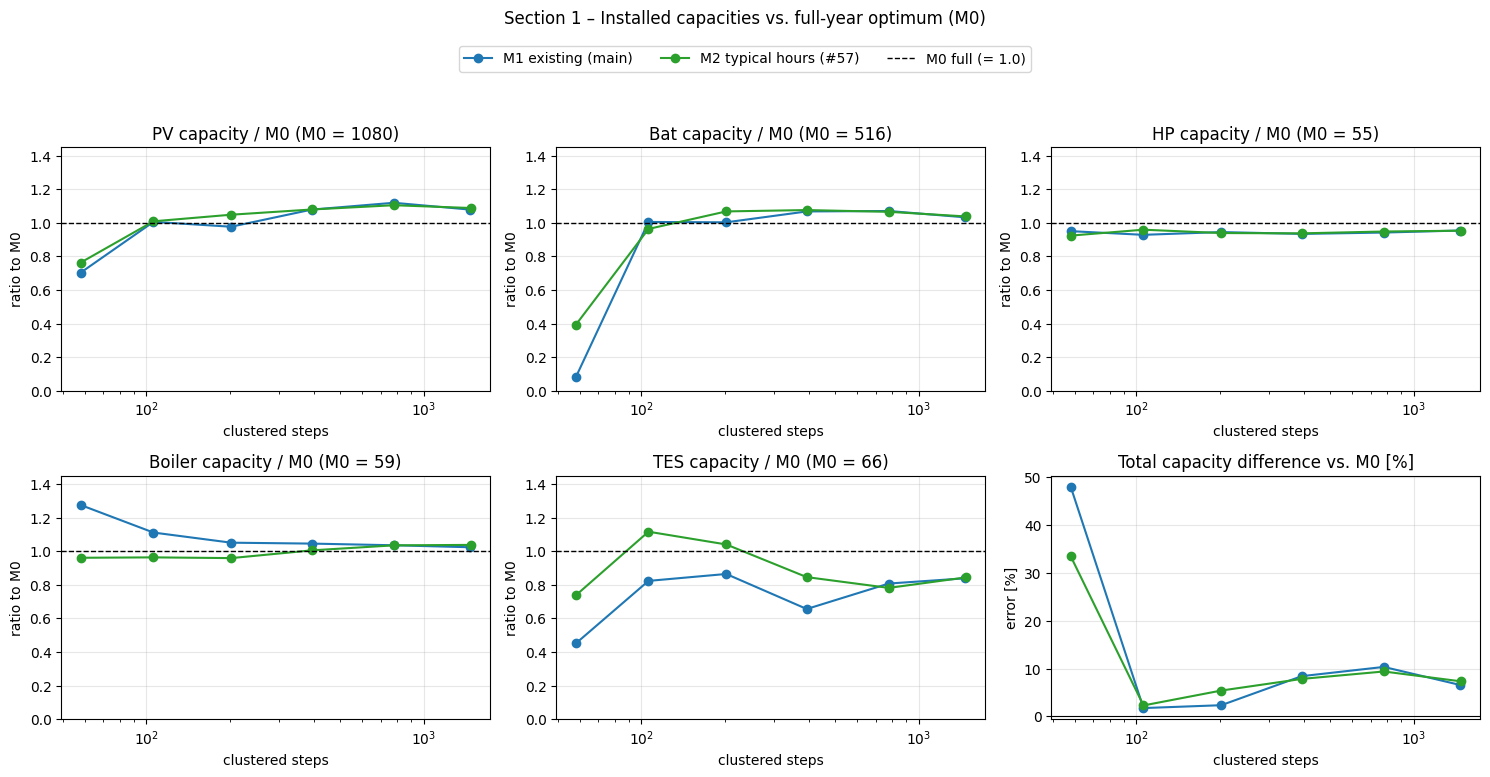

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for idx, t in enumerate(TECHS):
    ax = axes[idx // 3, idx % 3]
    m0_val = full["caps"].get(f"S1,H1,{t}", 0.0)
    for v in VARS:
        d = df[df.variant == v]
        ax.plot(d.num_ts, d[t] / m0_val, marker="o", color=COLORS[v], label=rl.LABELS[v])
    ax.axhline(1.0, color="k", ls="--", lw=1, label="M0 full (= 1.0)")
    ax.set_xscale("log"); ax.set_ylim(0, 1.45)
    ax.set_title(f"{t} capacity / M0 (M0 = {m0_val:.0f})"); ax.set_xlabel("clustered steps")
    ax.set_ylabel("ratio to M0"); ax.grid(True, alpha=0.3)
ax = axes[1, 2]
for v in VARS:
    d = df[df.variant == v]
    ax.plot(d.num_ts, d.cap_diff_pct, marker="o", color=COLORS[v], label=rl.LABELS[v])
ax.axhline(0, color="k", lw=0.8); ax.set_xscale("log")
ax.set_title("Total capacity difference vs. M0 [%]"); ax.set_xlabel("clustered steps")
ax.set_ylabel("error [%]"); ax.grid(True, alpha=0.3)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.99))
fig.suptitle("Section 1 – Installed capacities vs. full-year optimum (M0)", y=1.03)
plt.tight_layout(rect=[0, 0, 1, 0.94])

**Summary (Section 1):**
- At the smallest target (`K=48`, `58` steps), both methods under-build battery (`M2`: `202` kWh, `M1`: `41` kWh vs. `516` kWh in `M0`) and `PV` (`cap_diff`: `33.4 %` in `M2`, `47.9 %` in `M1`).
- From `K=96` (`106` steps) onward, both recover the full 5-technology mix within `2–10 %` total capacity difference (`M2` `K=96`: `cap_diff = 2.3 %`).
- `M2` slightly under-sizes `Boiler` (`56.5–56.8` kW vs. `58.9` kW in `M0` at `K=96–192`), whereas `M1` slightly over-sizes it (`62.0–65.5` kW).

## 2. Predicted cost error vs. true Design Regret

- **ROM cost error:** how far ROM's *own* objective sits from `M0`.
- **Design Regret:** extra cost when ROM's chosen capacities are operated over the real `8,760` h year.
- **Emergency backup heat (% of annual demand):** share of total heat demand (`202.1 MWh/yr`) served by expensive emergency backup (`5.0 CHF/kWh`) during cold-snap peaks.

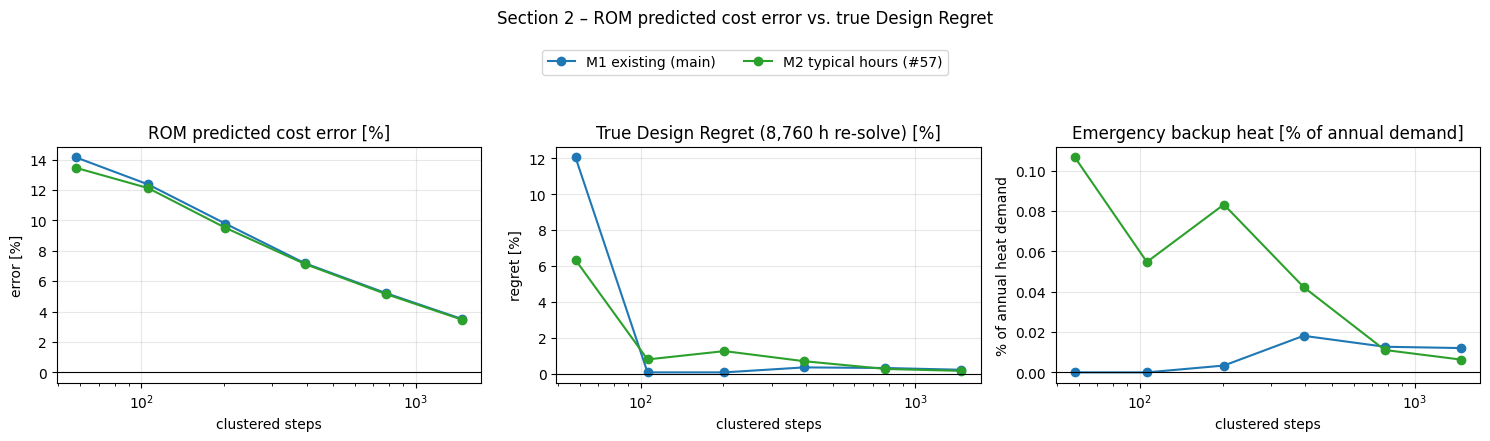

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for v in VARS:
    d = df[df.variant == v]
    axes[0].plot(d.num_ts, d.obj_err_pct, marker="o", color=COLORS[v], label=rl.LABELS[v])
    axes[1].plot(d.num_ts, d.regret_pct, marker="o", color=COLORS[v], label=rl.LABELS[v])
    axes[2].plot(d.num_ts, d.heat_bak_pct, marker="o", color=COLORS[v], label=rl.LABELS[v])
axes[0].axhline(0, color="k", lw=0.8); axes[0].set_xscale("log"); axes[0].set_title("ROM predicted cost error [%]"); axes[0].set_ylabel("error [%]")
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_xscale("log"); axes[1].set_title("True Design Regret (8,760 h re-solve) [%]"); axes[1].set_ylabel("regret [%]")
axes[2].axhline(0, color="k", lw=0.8); axes[2].set_xscale("log"); axes[2].set_title("Emergency backup heat [% of annual demand]"); axes[2].set_ylabel("% of annual heat demand")
for ax in axes:
    ax.set_xlabel("clustered steps"); ax.grid(True, alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.96))
fig.suptitle("Section 2 – ROM predicted cost error vs. true Design Regret", y=1.04)
plt.tight_layout(rect=[0, 0, 1, 0.88])

**Summary (Section 2):**
- **Crucial gap:** ROM's predicted cost error looks large (`+12.1 %` at `K=96`, `+9.5 %` at `K=192`), yet true **Design Regret is only `0.15–1.25 %`** for `M2` from `K=96` onward.
- **Relative backup heat is tiny (`≤ 0.11 %`), even in `M2`:** `0.11 %` (`K=48`), `0.05–0.08 %` (`K=96–192`), `0.04 %` (`K=384`), down to **`0.006 %`** at `K=1460` (better than `M1`'s `0.012 %`). Because emergency heat is priced at `5.0 CHF/kWh` (~40× normal heat cost), even `0.08 %` unmet heat adds `~0.8–1.2 %` to annual cost.
- **Why `M2` uses more backup heat than `M1` at small `K` (`48–384`):**
  - **`M2` (1-hour extreme + exact means):** locks only the single `131.4 kW` peak hour as its own cluster (`weight = 1`) and averages surrounding cold-snap hours (`122–127 kW`) down into regular clusters (`108–115 kW`). Since `TES` easily bridges one isolated peak hour, `M2` sizes `HP + Boiler` `4–6 kW` below `M0` (`107–109` vs. `113.5 kW`), leaving a small multi-hour cold-snap shortfall on the real year.
  - **`M1` (`new_cluster_center`):** pulls `5–12` near-peak hours into the `131.4 kW` peak cluster at `K=48–96`, exaggerating peak duration and accidentally **over-sizing `Boiler`** (`62–75 kW` vs. `58.9 kW` in `M0`) — masking shortfall at the cost of over-sizing and biased totals.

## Findings (E1b)

- **Key takeaway:**
  - Even when ROM's predicted cost error is `+9.5 %` to `+12.1 %` (`K=96–192`), **`M2` picks near-optimal investment sizes** with only **`0.15–1.25 %` true Design Regret**.
  - Extreme-hour protection prevents catastrophic under-sizing once `K ≥ 96` (`~106` steps); at `K=48` (`58` steps), battery capacity collapses (`-61 %` in `M2`, `-92 %` in `M1`) and regret jumps to `6.3–12.1 %`.
- **Why predicted cost error ≠ Design Regret:**
  - Typical-hour clustering makes storage look artificially restricted inside the ROM solve (inflating ROM operating cost), while still preserving the peak and price spread signals needed to size `PV`, `Bat`, `HP`, `Boiler`, and `TES` accurately.
- **Why `M2` shows slightly higher backup heat (`0.04–0.08 %`) at `K=96–384`:**
  - `M2` isolates only the single highest hour (`131.4 kW`, `weight = 1`), while nearby cold-snap hours (`122–127 kW`) get averaged into regular clusters (`108–115 kW`). `TES` covers the single isolated peak hour in ROM, so `HP + Boiler` is sized `3–6 kW` smaller (`108–110` vs. `113.5 kW` in `M0`).
  - By contrast, `M1` groups `5–12` near-peak hours into the `131.4 kW` peak cluster, accidentally over-sizing `Boiler` (`62–75 kW`) and hiding the shortfall until `K ≥ 768` — where `M2` resolves the cold-snap plateau and beats `M1` on both backup heat (`0.006 %` vs. `0.012 %`) and regret (`0.15 %` vs. `0.21 %`).